# Flux post-processing chain: sensible heat flux H (2016-2026.09)

**notebook version**: `1` (26 Oct 2026). Built from the CO2 flux notebook
`05_FPPC_IRGA72_NEE_2016-2026.09.ipynb` in this folder, which is adapted from the diive notebook
`FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

Processes the sensible heat flux `H` with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): quality
flags (L2), outliers (L3.2) and gap-filling with XGBoost and MDS (L4.1). As in FLUXNET2015 and
ONEFlux (Pastorello et al. 2020), `H` has no storage term (L3.1) and no USTAR filter (L3.3), and
there is no partitioning, uncertainty step or energy balance closure correction.
The site, flux, period and all settings are in *Settings*; *Data sources* links the site
documentation, which holds the decisions and periods specific to the site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet` in the
external data folder holds the Level-1 fluxes and the meteo data of the site.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.1.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2025
# Years to process. None processes the whole record; set from TEST_RUN, or give a list of years.
YEARS = [TEST_YEAR] if TEST_RUN else None

# The full record, asserted after loading when YEARS is None.
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "35_FPPC_IRGA72_H_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'H'  # sensible heat flux, from the sonic anemometer alone
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2
LONG_GAP_DAYS = 2  # gaps in the measured H at least this long are listed after loading

# --- Level 2 -----------------------------------------------------------------------------------
# The tests of the gas analyser (signal strength, gas completeness) do not apply to H. The raw-data
# tests read T_SONIC_VM97_TEST, the column of the base variable of H. Its absolute-limits test is
# added: a sonic temperature out of range points to water or ice on the transducers.
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': False},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': True, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included), with the reason for each.
REMOVE_DATES = [
    ['2018-12-20', '2018-12-26'],  # instrument boom not fixed in position, sonic could move
]
# Absolute limits (W m-2), chosen from the data: the upper limit keeps the largest daytime values
# that agree with SW_IN, the lower limit lies below the nighttime values of summer and removes the
# large negative values of wet and freezing episodes in winter.
ABSLIM = (-200, 800)

# --- Level 3.3 ---------------------------------------------------------------------------------
# No USTAR filter for H (Pastorello et al. 2020). Level 4.1 needs a Level-3.3 series, so the chain
# runs one scenario with threshold 0, which removes no record.
USTAR_THRESHOLDS = [0]
USTAR_SCENARIOS = ['CUT_NONE']
SCENARIO = USTAR_SCENARIOS[0]

# --- Level 4.1: meteo drivers ------------------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'W m-2'

# 30-min energy flux in W m-2 -> MJ m-2 per half-hour, for sums and cumulatives.
WM2_TO_MJ = 1800 * 1e-6

# MDS gap-filling, the method of FLUXNET2015 for H, next to XGBoost. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=42, n_jobs=-1, shap_max_rows=5000)

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    init_flux_data,
    make_level32_detector,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-29 11:00:42
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"
else:
    assert (df.index[0], df.index[-1]) == (pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)), \
        f"the input runs from {df.index[0]} to {df.index[-1]}, not {PERIOD_START} to {PERIOD_END}"

for _c in [FLUXCOL, 'FC', TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG, VPD_FLAG,
           f'{FLUXCOL}_SSITC_TEST', f'{FLUXCOL}_SCF', 'T_SONIC_VM97_TEST']:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet (0.370 seconds).

188,448 records x 347 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
H: 179,251 records


### 📋 Table: records of H per year

The measured `H` of each year before any test, the days without a single `H` record, and the
records of `H` that have no `FC`, mostly from periods in which only the gas analyser failed.

In [4]:
_h = df[FLUXCOL].notna()
_year = df.index.year
_days = _h.groupby(df.index.normalize()).sum()
COVERAGE = pd.DataFrame({
    'records': _h.groupby(_year).size(),
    'measured': _h.groupby(_year).sum(),
    'measured %': (100 * _h.groupby(_year).mean()).round(1),
    'days without H': (_days == 0).groupby(_days.index.year).sum(),
    'without FC': (_h & df['FC'].isna()).groupby(_year).sum(),
})
COVERAGE.index.name = 'year'
display(COVERAGE)

,records,measured,measured %,days without H,without FC
year,,,,,
2016,17568,16876,96.1,10,498
2017,17520,17285,98.7,0,219
2018,17520,17194,98.1,0,1295
2019,17520,13978,79.8,68,376
2020,17568,17433,99.2,0,1308
2021,17520,16507,94.2,18,204
2022,17520,15572,88.9,37,347
2023,17520,16916,96.6,9,37
2024,17568,16993,96.7,8,50


### 📋 Table: long gaps in H

Every period of at least `LONG_GAP_DAYS` days without a measured `H` in the input, including one at
the start or end of the processed period.

In [5]:
# Runs of records without H: a new run starts wherever H changes between measured and missing.
_miss = ~_h
_run = (_miss != _miss.shift()).cumsum()[_miss]
_g = df.index.to_series()[_miss].groupby(_run)
LONG_GAPS = pd.DataFrame({'first missing': _g.min(), 'last missing': _g.max(), 'records': _g.size()})
LONG_GAPS['days'] = (LONG_GAPS['records'] / 48).round(1)
LONG_GAPS = LONG_GAPS[LONG_GAPS['days'] >= LONG_GAP_DAYS].reset_index(drop=True)
display(LONG_GAPS)

,first missing,last missing,records,days
0,2016-01-01 00:15:00,2016-01-11 15:15:00,511,10.6
1,2019-01-10 15:15:00,2019-03-20 18:45:00,3320,69.2
2,2021-12-13 19:15:00,2022-02-07 10:45:00,2672,55.7
3,2023-11-01 12:15:00,2023-11-08 16:15:00,345,7.2
4,2023-12-03 08:15:00,2023-12-07 14:45:00,206,4.3
5,2024-03-25 08:45:00,2024-04-02 11:45:00,391,8.1


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [6]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: H ─────────────────────────────────────

> Detected base variable T_SONIC for H. (T_SONIC was used to calculate H.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'H'
  levels run  = []
  fpc_df      = 188448 rows x 5 cols
  columns     = [H, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`: steady state and developed turbulence (SSITC), the spectral
correction factor, and spikes, dropouts and absolute limits in the raw sonic temperature (Vickers
and Mahrt 1997). The tests of the gas analyser do not apply to `H`. The table shows how many records
each test removes.

In [7]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_H_SSITC_TEST, values taken from output variable 
H_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_H_SCF_TEST, newly 
calculated from output variable H_SCF, with flag 0 (good values) where H_SCF < 2, flag 1 (ok values)
where H_SCF >= 2 and < 4, flag 2 (bad values) where H_SCF >= 4...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_SPIKE_HF_TEST, values taken 
from output variable T_SONIC_VM97_TEST from position 1, based on T_SONIC, with flag 0 (good values) 
where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) 
where test failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_DROPOUT_HF_TEST, values taken 
from output variable T_SONIC_VM97_TEST from position 3, based on T_SONIC, with flag 0 (good values) 
where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) 
where test failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF_TEST, 
values taken from output variable T_SONIC_VM97_TEST from position 4, based on T_SONIC, with flag 0 
(good values) where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 
(ok values) where test failed (for soft flags) ...

After L2: 149,985 valid records


### 📊 Plot: Level-2 quality flag over time

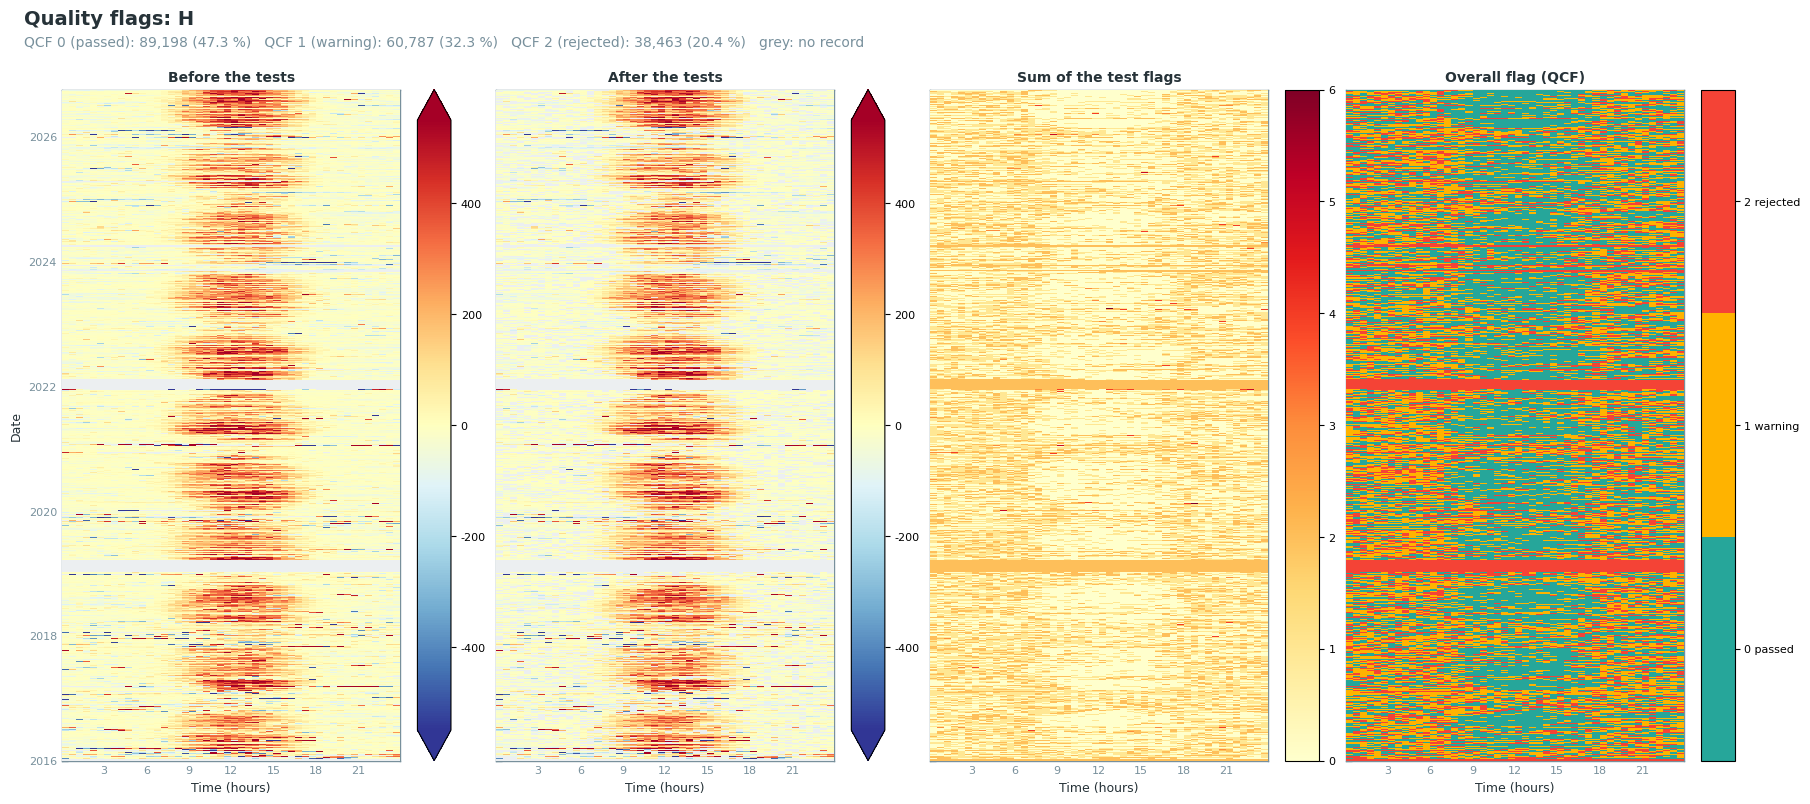

In [8]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [9]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: H
Measured records: 179,251 of 188,448
Missing records: 9,197 (4.88 %), flagged by the missing-values test
                                                             Pass     Warn     Fail    Fail      Not
Test                                   Period    Tested       (0)      (1)      (2)       %   tested
────────────────────────────────────────────────────────────────────────────────────────────────────
L2_H_SSITC                             all      179,251    89,576   61,082   28,593   15.95        0
                                       day       90,674    53,450   25,758   11,466   12.65        0
                                       night     88,577    36,126   35,324   17,127   19.34        0
                                                                                                    
L2_H_SCF                               all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_SPIKE_HF             all      179,251   178,568        0      683    0.38        0
                                       day       90,674    90,319        0      355    0.39        0
                                       night     88,577    88,249        0      328    0.37        0
                                                                                                    
L2_H_T_SONIC_VM97_DROPOUT_HF           all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF   all      179,251   179,064        0      187    0.10        0
                                       day       90,674    90,585        0       89    0.10        0
                                       night     88,577    88,479        0       98    0.11        0

## Step 3: no storage term (Level 3.1)

`H` has no storage term, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020). Levels 3.2 and
3.3 need Level 3.1, so `run_level31` runs with `set_storage_to_zero=True`: the column `H_L3.1`
equals `H` ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term)).

In [10]:
data = run_level31(data, set_storage_to_zero=True, gapfill_storage_term=False)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux H_L3.1 from flux H + storage term set to zero

After L3.1: 149,985 valid records (col: H_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reason for each is given in *Settings*.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.

Negative nighttime values are not tested: a negative `H` at night is physical. How the tests work:
[diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists further tests.

In [11]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

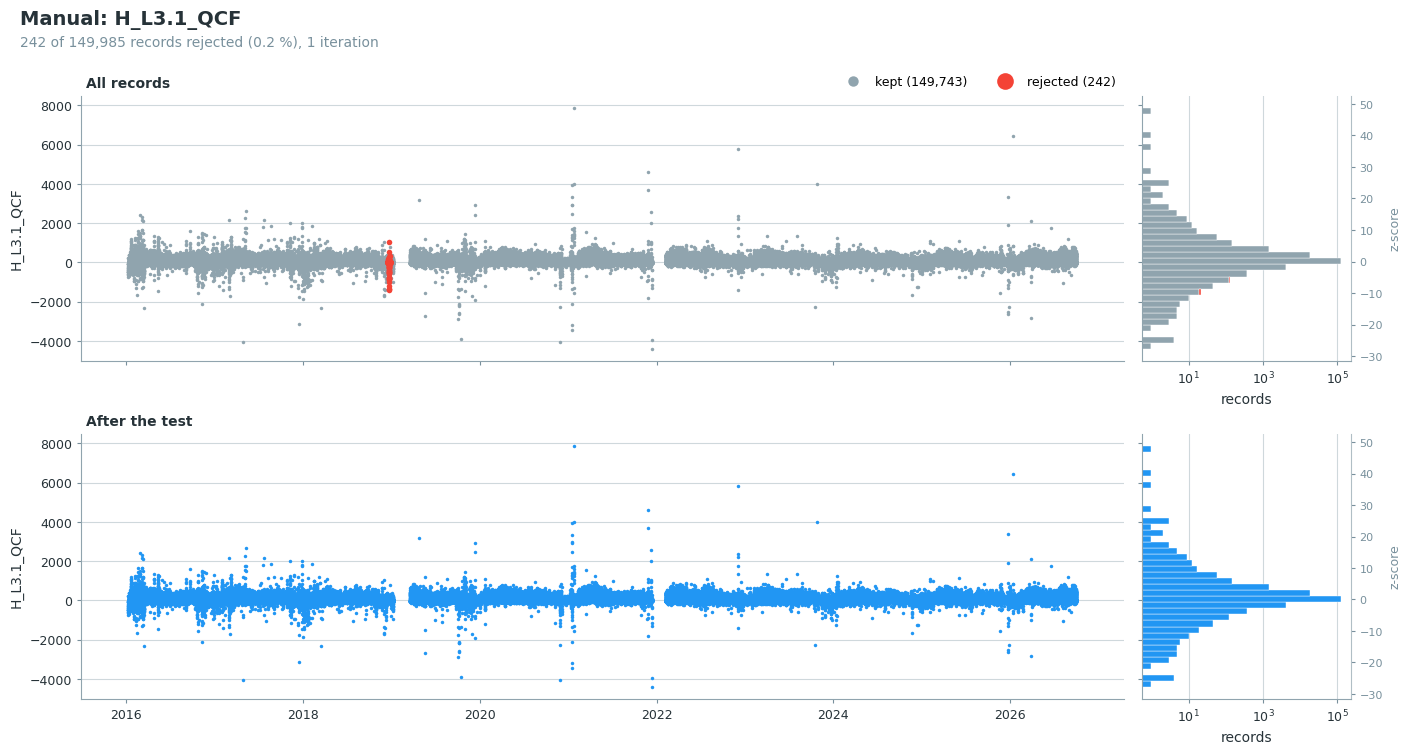

In [12]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [13]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

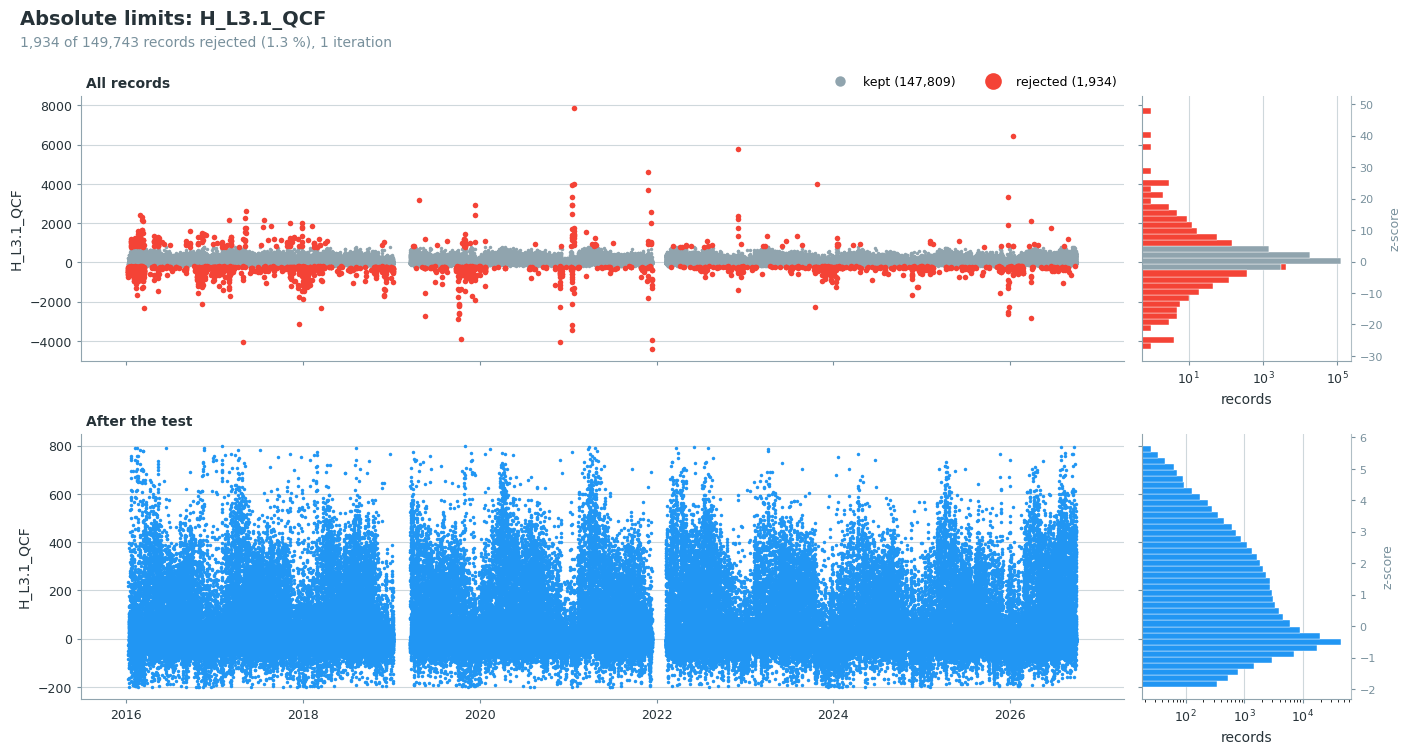

In [14]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  3515 (  2.38%) | Day:  1222 | Night:  2293

[Dt/Nt] ITER #02 | Outliers:   471 (  0.33%) | Day:   181 | Night:   290

[Dt/Nt] ITER #03 | Outliers:    95 (  0.07%) | Day:    28 | Night:    67

[Dt/Nt] ITER #04 | Outliers:    33 (  0.02%) | Day:     9 | Night:    24

[Dt/Nt] ITER #05 | Outliers:     5 (  0.00%) | Day:     4 | Night:     1

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

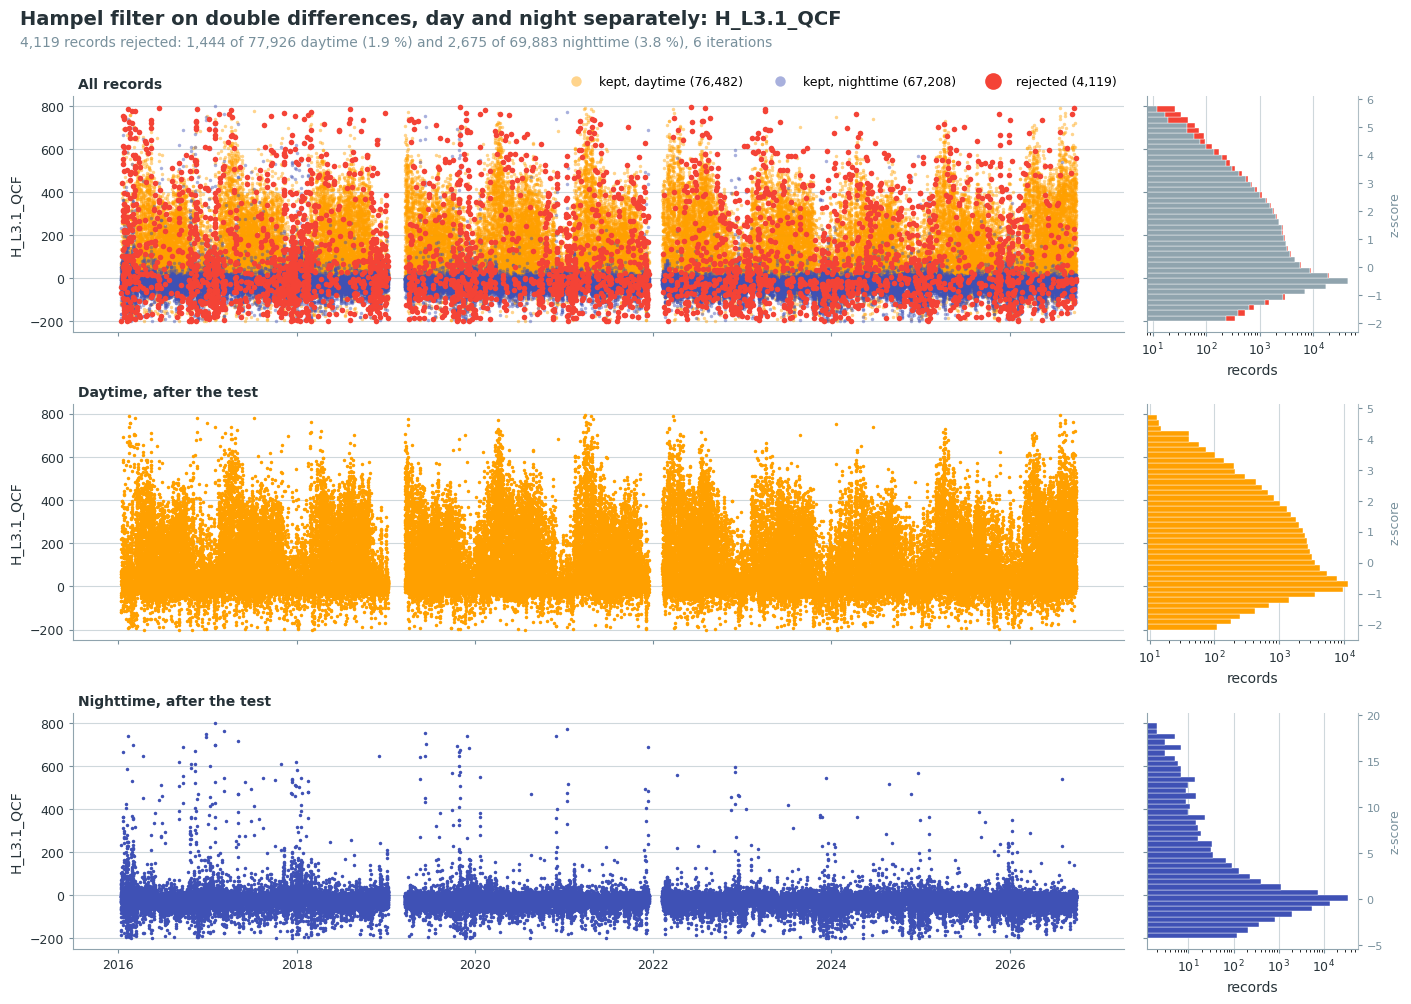

In [16]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [17]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2215 (  1.54%) | Day:   625 | Night:  1590

[Dt/Nt] ITER #02 | Outliers:   323 (  0.23%) | Day:    84 | Night:   239

[Dt/Nt] ITER #03 | Outliers:    77 (  0.05%) | Day:    22 | Night:    55

[Dt/Nt] ITER #04 | Outliers:    21 (  0.01%) | Day:     7 | Night:    14

[Dt/Nt] ITER #05 | Outliers:     6 (  0.00%) | Day:     3 | Night:     3

[Dt/Nt] ITER #06 | Outliers:     2 (  0.00%) | Day:     1 | Night:     1

[Dt/Nt] ITER #07 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 4 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

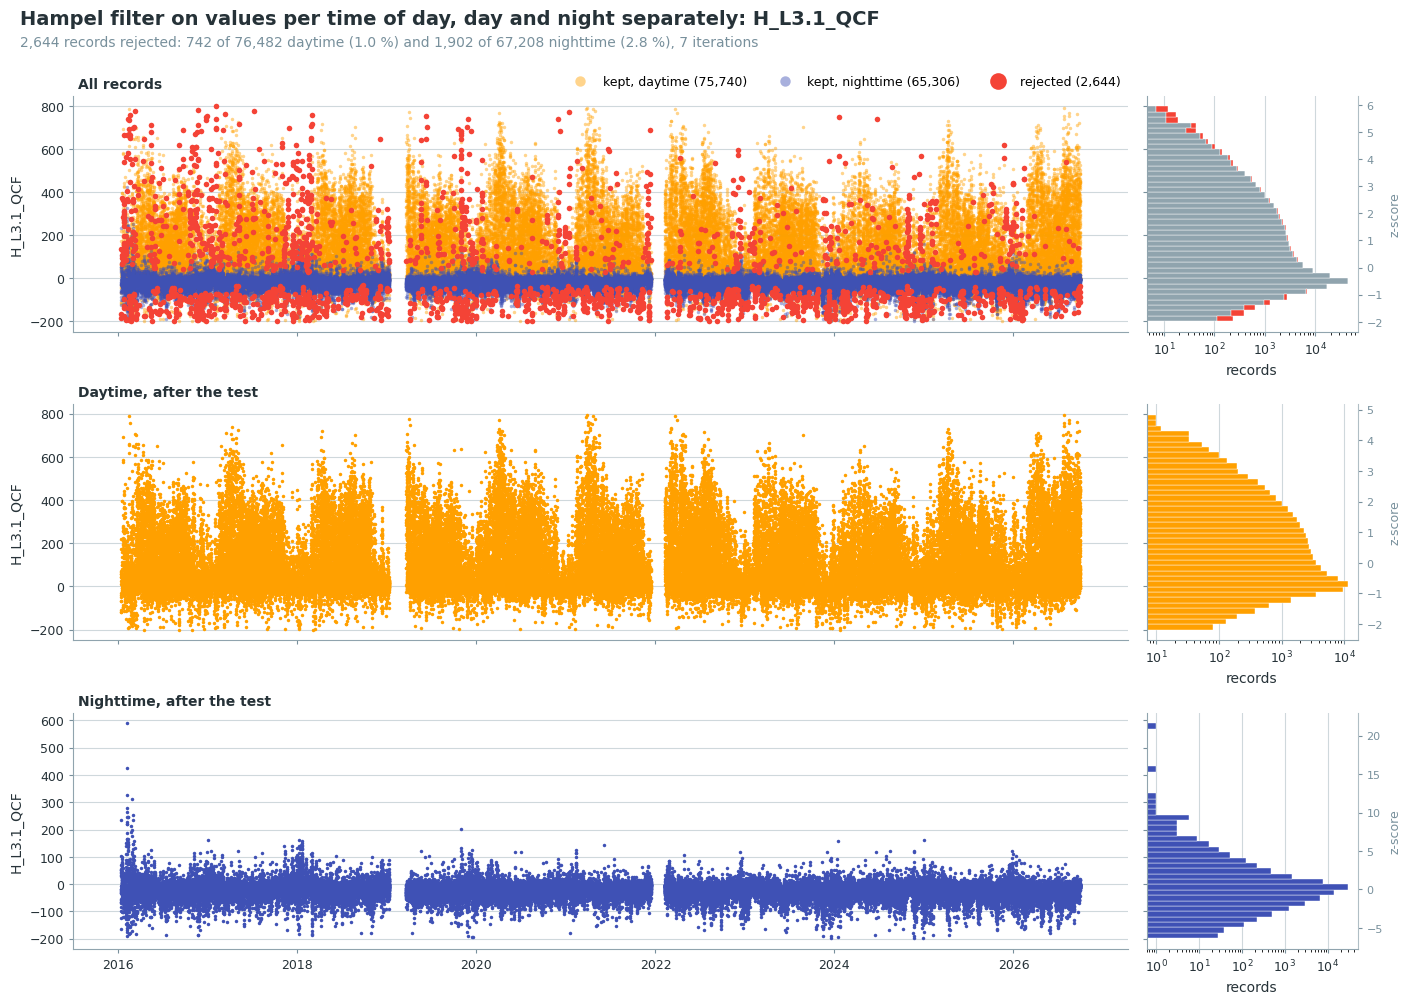

In [18]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [19]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [20]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [21]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 141,046 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

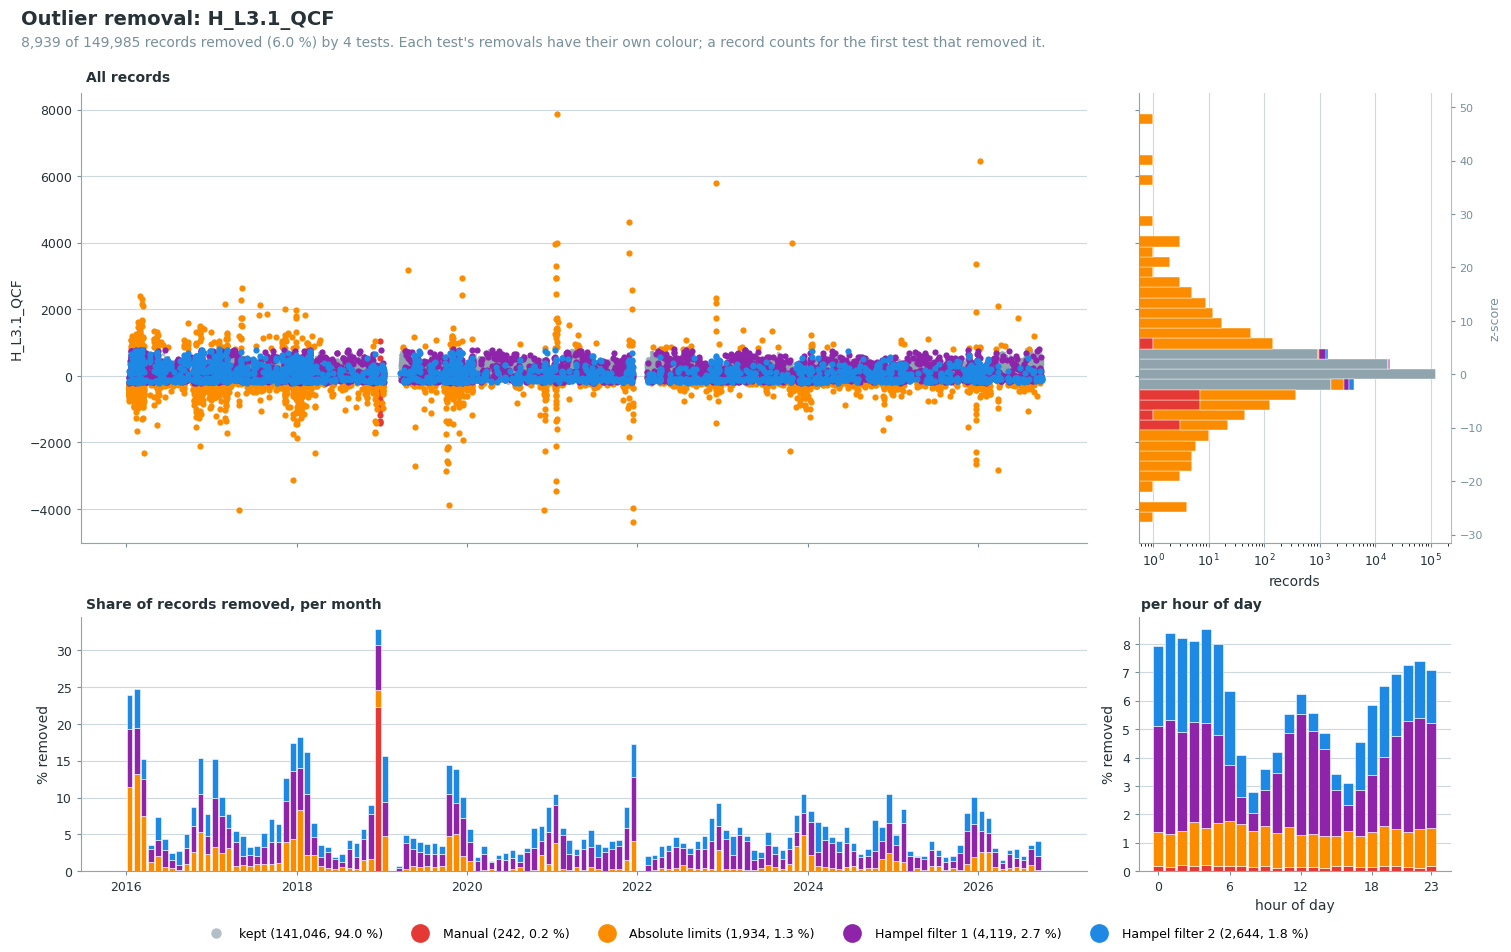

In [22]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

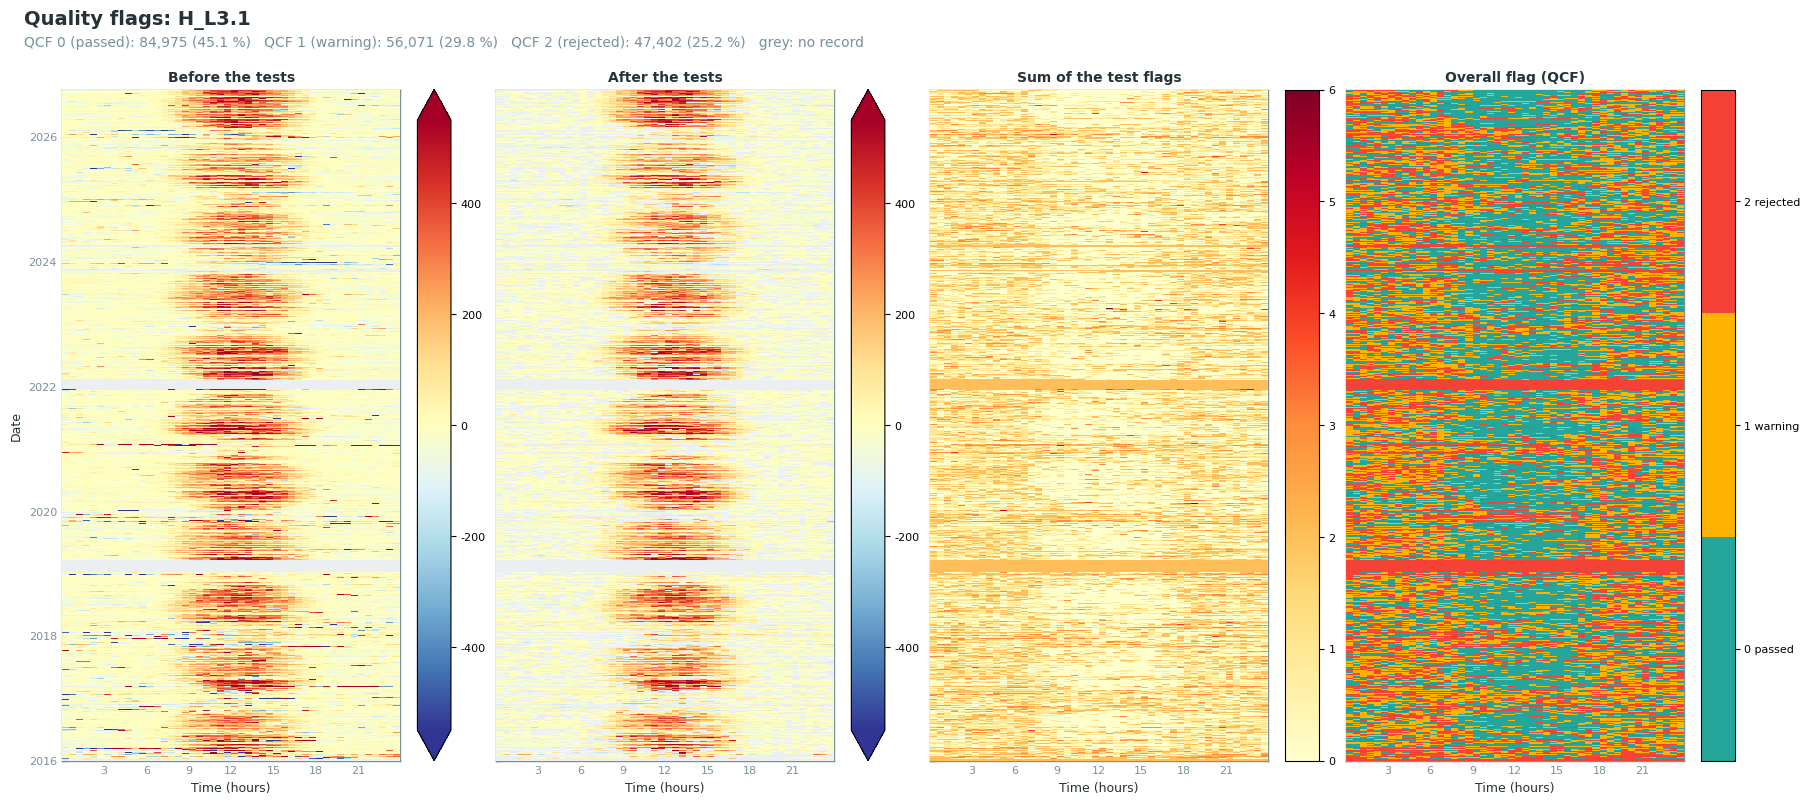

In [23]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [24]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: H_L3.1
Measured records: 179,251 of 188,448
Missing records: 9,197 (4.88 %), flagged by the missing-values test
                                                             Pass     Warn     Fail    Fail      Not
Test                                   Period    Tested       (0)      (1)      (2)       %   tested
────────────────────────────────────────────────────────────────────────────────────────────────────
L2_H_SSITC                             all      179,251    89,576   61,082   28,593   15.95        0
                                       day       90,674    53,450   25,758   11,466   12.65        0
                                       night     88,577    36,126   35,324   17,127   19.34        0
                                                                                                    
L2_H_SCF                               all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_SPIKE_HF             all      179,251   178,568        0      683    0.38        0
                                       day       90,674    90,319        0      355    0.39        0
                                       night     88,577    88,249        0      328    0.37        0
                                                                                                    
L2_H_T_SONIC_VM97_DROPOUT_HF           all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF   all      179,251   179,064        0      187    0.10        0
                                       day       90,674    90,585        0       89    0.10        0
                                       night     88,577    88,479        0       98    0.11        0
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_MANUAL         all      149,985   149,743        0      242    0.16   29,266
                                       day       78,870    78,791        0       79    0.10   11,804
                                       night     71,115    70,952        0      163    0.23   17,462
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_ABSLIM         all      149,743   147,809        0    1,934    1.29   29,508
                                       day       78,791    77,926        0      865    1.10   11,883
                                       night     70,952    69,883        0    1,069    1.51   17,625
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_HAMPEL         all      147,809   143,690        0    4,119    2.79   31,442
                                       day       77,926    76,482        0    1,444    1.85   12,748
                                       night     69,883    67,208        0    2,675    3.83   18,694
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_2       all      143,690   141,046        0    2,644    1.84   35,561
                                       day       76,482    75,740        0      742    0.97   14,192
                                       night     67,208    65,306        0    1,902    2.83   21,369

## Step 5: no USTAR filter (Level 3.3)

No USTAR filter for `H`, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020). Level 4.1 reads
Level 3.3, so the chain runs one scenario, `CUT_NONE`, with threshold 0, which removes no record.
Column names carry `_L3.3_CUT_NONE_` ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [25]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_NONE

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records for gap-filling

In [26]:
report_gapfilling_input(data);

Records for gap-filling
                      removed:   removed:              used:    used:    used:    used:
USTAR      measured      tests      USTAR      used    QCF 0    QCF 1      day    night
───────────────────────────────────────────────────────────────────────────────────────
CUT_NONE    179,251     38,205          0   141,046   84,975   56,071   75,740   65,306
                95%        20%         0%       75%      45%      30%      40%      35%
Records, and their share of all 188,448 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

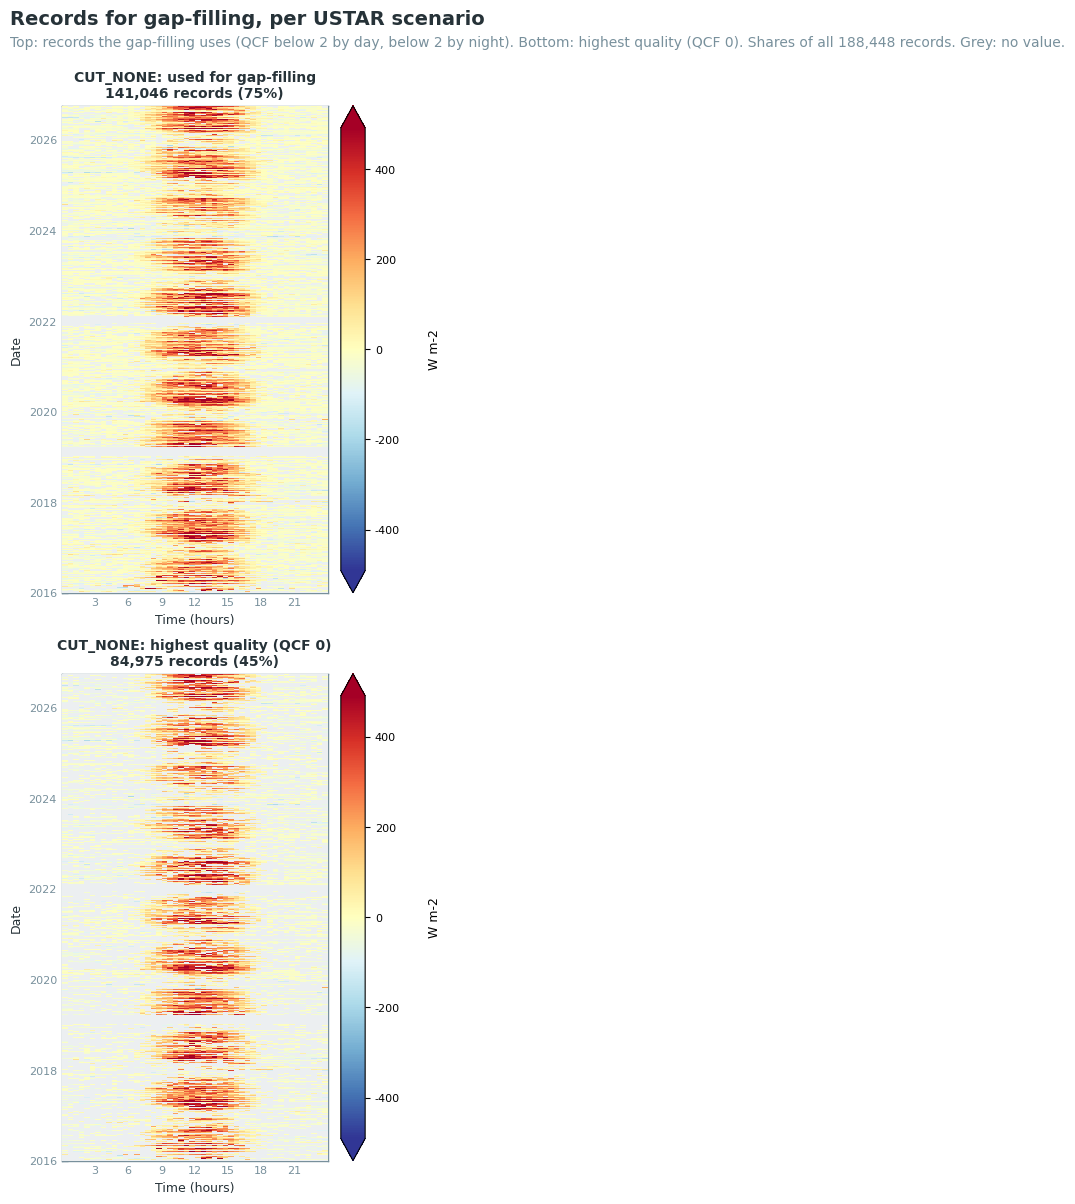

In [27]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps to fill

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [28]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR      missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
───────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE        25.2   22849          13                 69.2           Jan                    42.3
A long gap lasts at least 1 day.

## Step 6: model features

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is built once and passed to XGBoost. `target_col` is only a placeholder.

In [29]:
engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

## Step 7: gap-filling (Level 4.1)

XGBoost and MDS fill the gaps; MDS is the method of FLUXNET2015 and ONEFlux for the energy fluxes
(Pastorello et al. 2020). Step 10 compares the two.

### XGBoost

One model per year, trained on three years, with features selected by SHAP
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [30]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [31]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: results

How many records were measured and how many were filled, then the annual sum of the flux. The
share measured is given in brackets: a year with long gaps rests largely on the model. An incomplete
year is marked.

### 📋 Table: measured and filled records

In [32]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR      records   measured   filled   filled %
───────────────────────────────────────────────────────────
MDS       CUT_NONE   188,448    141,046   47,402       25.2
XGBoost   CUT_NONE   188,448    141,046   47,402       25.2
MDS (CUT_NONE): H_L3.1_L3.3_CUT_NONE_QCF -> H_L3.1_L3.3_CUT_NONE_QCF_gfMDS
XGBoost (CUT_NONE): H_L3.1_L3.3_CUT_NONE_QCF -> H_L3.1_L3.3_CUT_NONE_QCF_gfXG

### 📋 Table: annual sums of the flux

In [33]:
report_annual_sums(data, gain=WM2_TO_MJ, units='MJ m-2');

Annual sums (MJ m-2)
                 MDS       XGBoost
year        CUT_NONE      CUT_NONE
──────────────────────────────────
2016     1,070 (72%)   1,116 (72%)
2017     1,295 (75%)   1,302 (75%)
2018     1,283 (75%)   1,298 (75%)
2019     1,153 (61%)   1,172 (61%)
2020     1,380 (81%)   1,381 (81%)
2021     1,221 (75%)   1,209 (75%)
2022     1,443 (72%)   1,432 (72%)
2023     1,016 (78%)   1,022 (78%)
2024       800 (76%)     792 (76%)
2025     1,067 (79%)   1,053 (79%)
2026 *   1,365 (81%)   1,366 (81%)
In brackets: the share of the year's records that were measured.
* Incomplete year (2026): the sum covers only part of it.

## Step 9: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [34]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
XGBoost   CUT_NONE   2016   0.817   51.18   31.14   17.68   600.5
XGBoost   CUT_NONE   2017   0.817   51.18   31.14   17.68   600.5
XGBoost   CUT_NONE   2018   0.839   48.12   29.66   17.04   602.3
XGBoost   CUT_NONE   2019   0.869   43.65   27.73   16.31   555.6
XGBoost   CUT_NONE   2020   0.878   43.03   27.22   15.98   555.6
XGBoost   CUT_NONE   2021   0.888   43.99   27.89   16.17   369.4
XGBoost   CUT_NONE   2022   0.881   44.21   28.11   16.48   347.4
XGBoost   CUT_NONE   2023   0.868   43.97   28.19   16.61   341.7
XGBoost   CUT_NONE   2024   0.862   41.37   26.67   16.11   445.0
XGBoost   CUT_NONE   2025   0.879   43.79   28.45   17.08   463.0
XGBoost   CUT_NONE   2026   0.879   43.79   28.45   17.08   463.0
XGBoost   CUT_NONE   mean   0.862   45.30   28.61   16.75   485.8
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_NONE).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [35]:
report_model_overview(data);

Gap-filling models
                  trained                                           final    test    test            fall-
USTAR      year   on          features    train     test   trees      fit      R²    RMSE   filled    back
──────────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   2016   2016-2018         87   29,124    9,704     120   38,828   0.817   51.18    4,963       0
CUT_NONE   2017   2016-2018         87   29,124    9,704     120   38,828   0.817   51.18    4,373       0
CUT_NONE   2018   2017-2019         87   27,818    9,139     120   36,957   0.839   48.12    4,444       0
CUT_NONE   2019   2018-2020         87   28,697    9,278     120   37,975   0.869   43.65    6,786       0
CUT_NONE   2020   2019-2021         87   28,672    9,288     120   37,960   0.878   43.03    3,403       0
CUT_NONE   2021   2020-2022         87   29,983    9,922     120   39,905   0.888   43.99    4,459       0
CUT_NONE   2022   2021-2023         87   29,478    9,922     120   39,400   0.881   44.21    4,841       0
CUT_NONE   2023   2022-2024         87   29,666   10,045     120   39,711   0.868   43.97    3,860       0
CUT_NONE   2024   2023-2025         87   30,669   10,265     120   40,934   0.862   41.37    4,196       0
CUT_NONE   2025   2024-2026         87   28,325    9,594     120   37,919   0.879   43.79    3,618       0
CUT_NONE   2026   2024-2026         87   28,325    9,594     120   37,919   0.879   43.79    2,459       0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, which 
the model did not see.
trees: 120 for every model, chosen by blocked cross-validation (report_tree_selection).
final fit: the gaps are filled by a model refitted on all complete records with that number of trees. 
filled / fallback: gaps of the model year filled by this model, or by the fallback model on timestamp 
features where a driver was missing.
XGBoost: learning_rate=0.05, max_depth=6, n_estimators=120, n_jobs=-1, random_state=42

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [36]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2016-2018    29,124     55.49     33.52     0.788    51.18    0.817
2017-2019    27,818     51.19     31.80     0.821    48.12    0.839
2018-2020    28,697     49.76     31.43     0.841    43.65    0.869
2019-2021    28,672     47.41     30.01     0.857    43.03    0.878
2020-2022    29,983     47.98     30.40     0.867    43.99    0.888
2021-2023    29,478     47.42     30.24     0.859    44.21    0.881
2022-2024    29,666     45.72     29.77     0.852    43.97    0.868
2023-2025    30,669     44.40     28.84     0.838    41.37    0.862
2024-2026    28,325     48.35     30.95     0.844    43.79    0.879
120 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to
1000 tested). USTAR scenario CUT_NONE.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

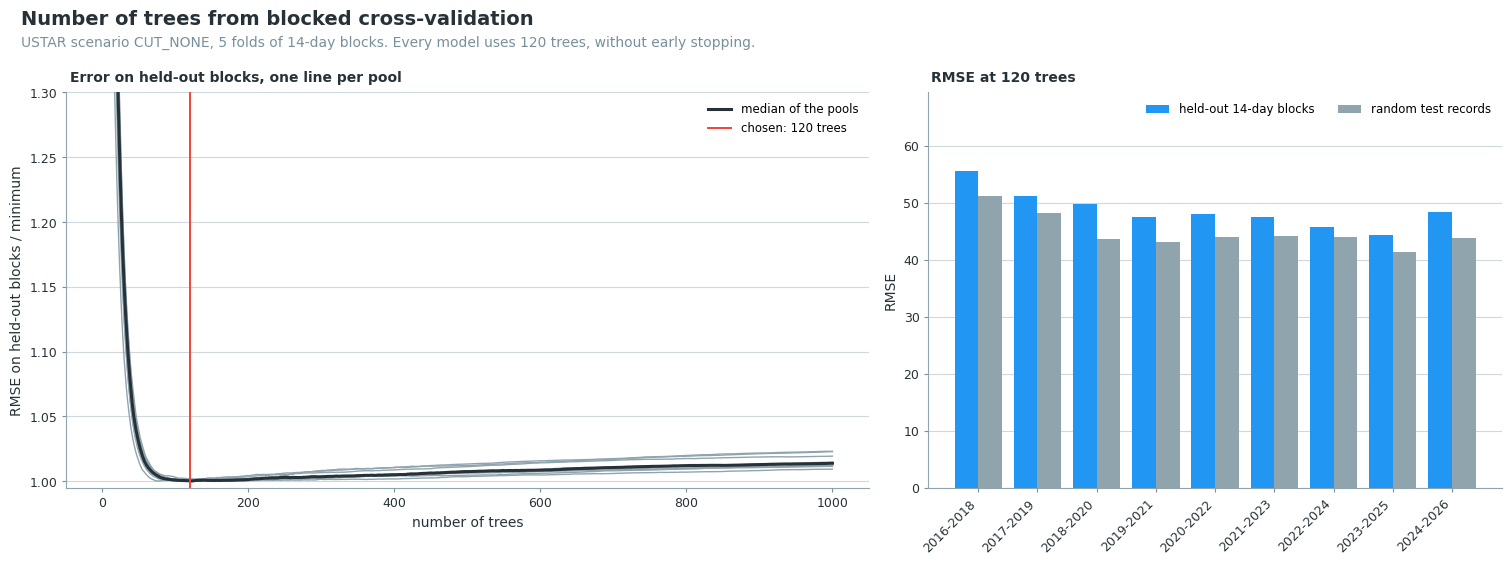

In [37]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [38]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
MDS       CUT_NONE   all    0.837   49.97   31.34   18.19   709.8
XGBoost   CUT_NONE   2016   0.865   44.18   28.10   16.92   551.7
XGBoost   CUT_NONE   2017   0.865   44.18   28.10   16.92   551.7
XGBoost   CUT_NONE   2018   0.884   41.17   26.67   16.39   491.9
XGBoost   CUT_NONE   2019   0.900   39.11   25.79   16.06   537.0
XGBoost   CUT_NONE   2020   0.909   37.61   24.77   15.39   503.7
XGBoost   CUT_NONE   2021   0.915   38.19   25.31   15.58   393.6
XGBoost   CUT_NONE   2022   0.912   37.70   25.06   15.78   697.9
XGBoost   CUT_NONE   2023   0.905   36.89   24.91   15.99   647.8
XGBoost   CUT_NONE   2024   0.896   35.61   24.11   15.67   599.7
XGBoost   CUT_NONE   2025   0.908   37.53   25.39   16.28   307.4
XGBoost   CUT_NONE   2026   0.908   37.53   25.39   16.28   307.4
XGBoost   CUT_NONE   mean   0.897   39.06   25.78   16.11   508.1
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [39]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2016         2016-2018              
2017         2016-2018              
2018         2017-2019              
2019         2018-2020              
2020         2019-2021              
2021         2020-2022              
2022         2021-2023              
2023         2022-2024              
2024         2023-2025              
2025         2024-2026              
2026         2024-2026              
Not available for MDS (CUT_NONE) (does not pool years).

### 📋 Table: most important features (SHAP)

In [40]:
report_gapfilling_feature_importances(data, ustar_scenario=SCENARIO)

Feature importances, XGBoost (CUT_NONE): top 10 of 87 features, mean |SHAP|
 #   feature                                   2016    2017    2018    2019    2020    2021    2022    2023    2024    2025    2026    mean
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                       51.73   51.73   48.22   58.51   54.75   59.36   48.65   43.44   40.36   42.24   42.24   49.20
 2   .SW_IN_T1_47_1_gfXG_MEAN2                16.46   16.46   18.38   19.58   22.07   22.11   29.04   23.97   21.17   22.91   22.91   21.37
 3   .SW_IN_T1_47_1_gfXG_ROLLMIN2              4.29    4.29    6.17    3.71    6.27    8.32    7.36    9.83   10.40   18.52   18.52    8.88
 4   .DOY_COS                                  6.99    6.99    6.86    7.31    5.41    5.43    4.81    4.80    7.30    9.57    9.57    6.82
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX2              4.53    4.53    3.43    4.32    5.87    3.53    2.89    2.24    2.12    3.11    3.11    3.61
 6   .HOUR_COS                                 6.74    6.74    6.67    4.22    2.99    2.13    0.92    0.85    0.51    0.59    0.59    3.00
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4              3.39    3.39    3.00    1.07    0.43    3.50    4.77    4.55    2.54    1.48    1.48    2.69
 8   .WEEK_COS                                 1.62    1.62    0.30    1.04    4.19    4.08    3.40    1.79    0.65    1.64    1.64    2.00
 9   .DOY_SIN                                  1.24    1.24    2.23    2.77    2.40    1.71    2.30    1.75    1.78    1.73    1.73    1.90
10   .TA_T1_47_1_HOMOGENIZED_gfXG_ROLLMIN24    0.97    0.97    0.62    0.53    0.73    0.85    2.43    3.57    2.80    2.35    2.35    1.65

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_NONE) (no model trained).

### 📊 Plot: feature ranks per year

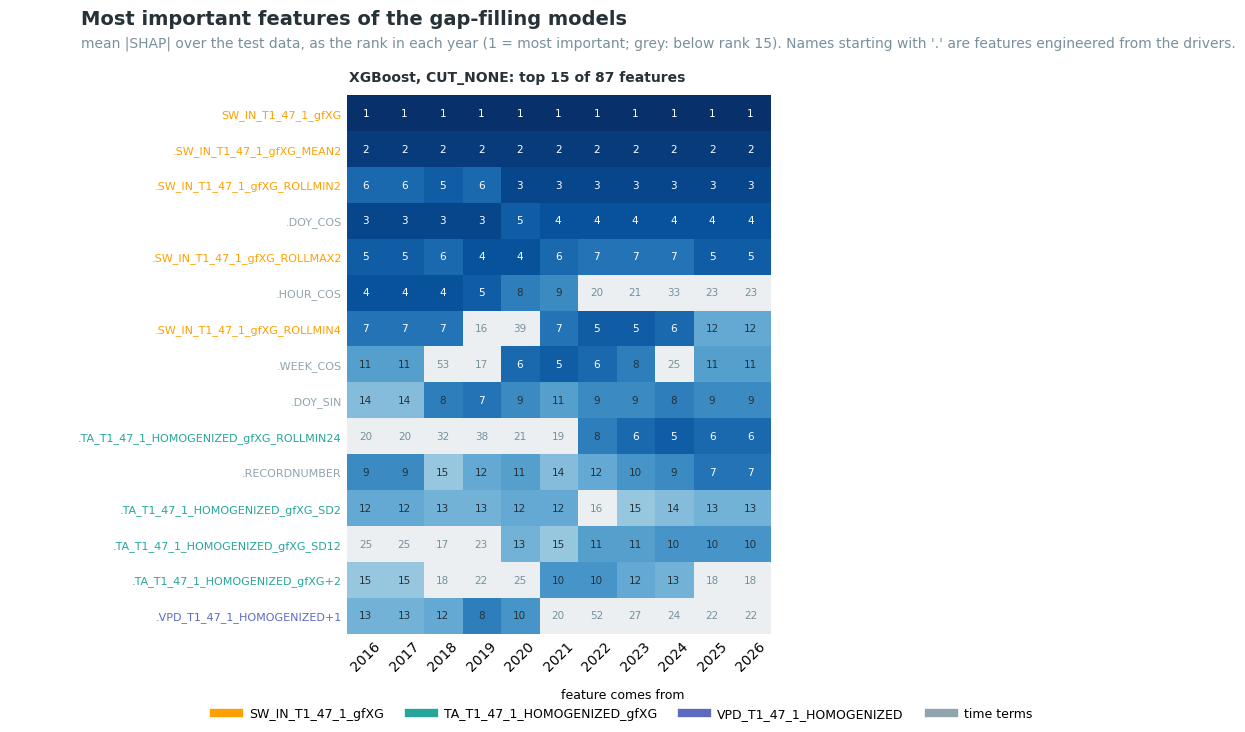

In [41]:
plot_feature_ranks_per_year(data)

## Step 10: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

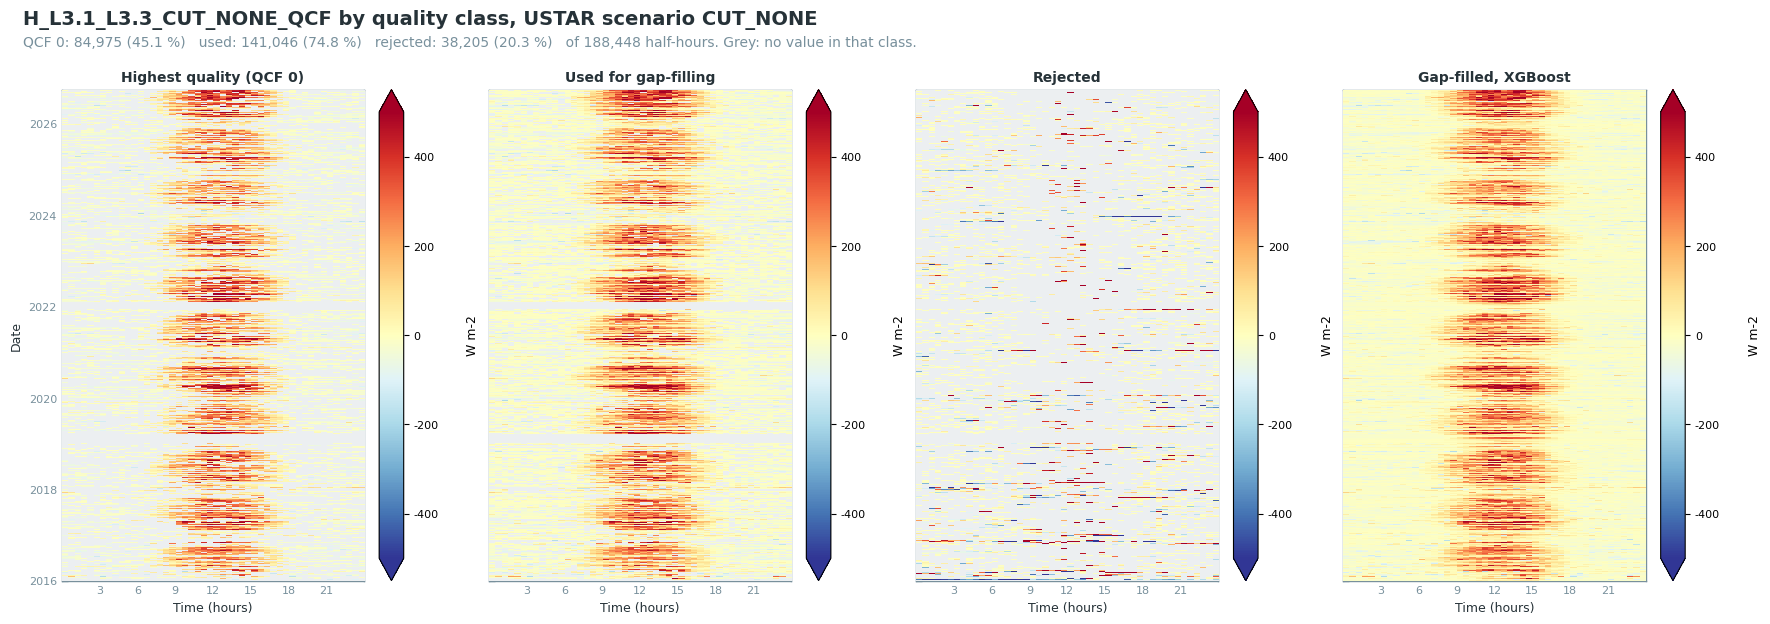

In [42]:
plot_quality_heatmaps(data, ustar_scenario=SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

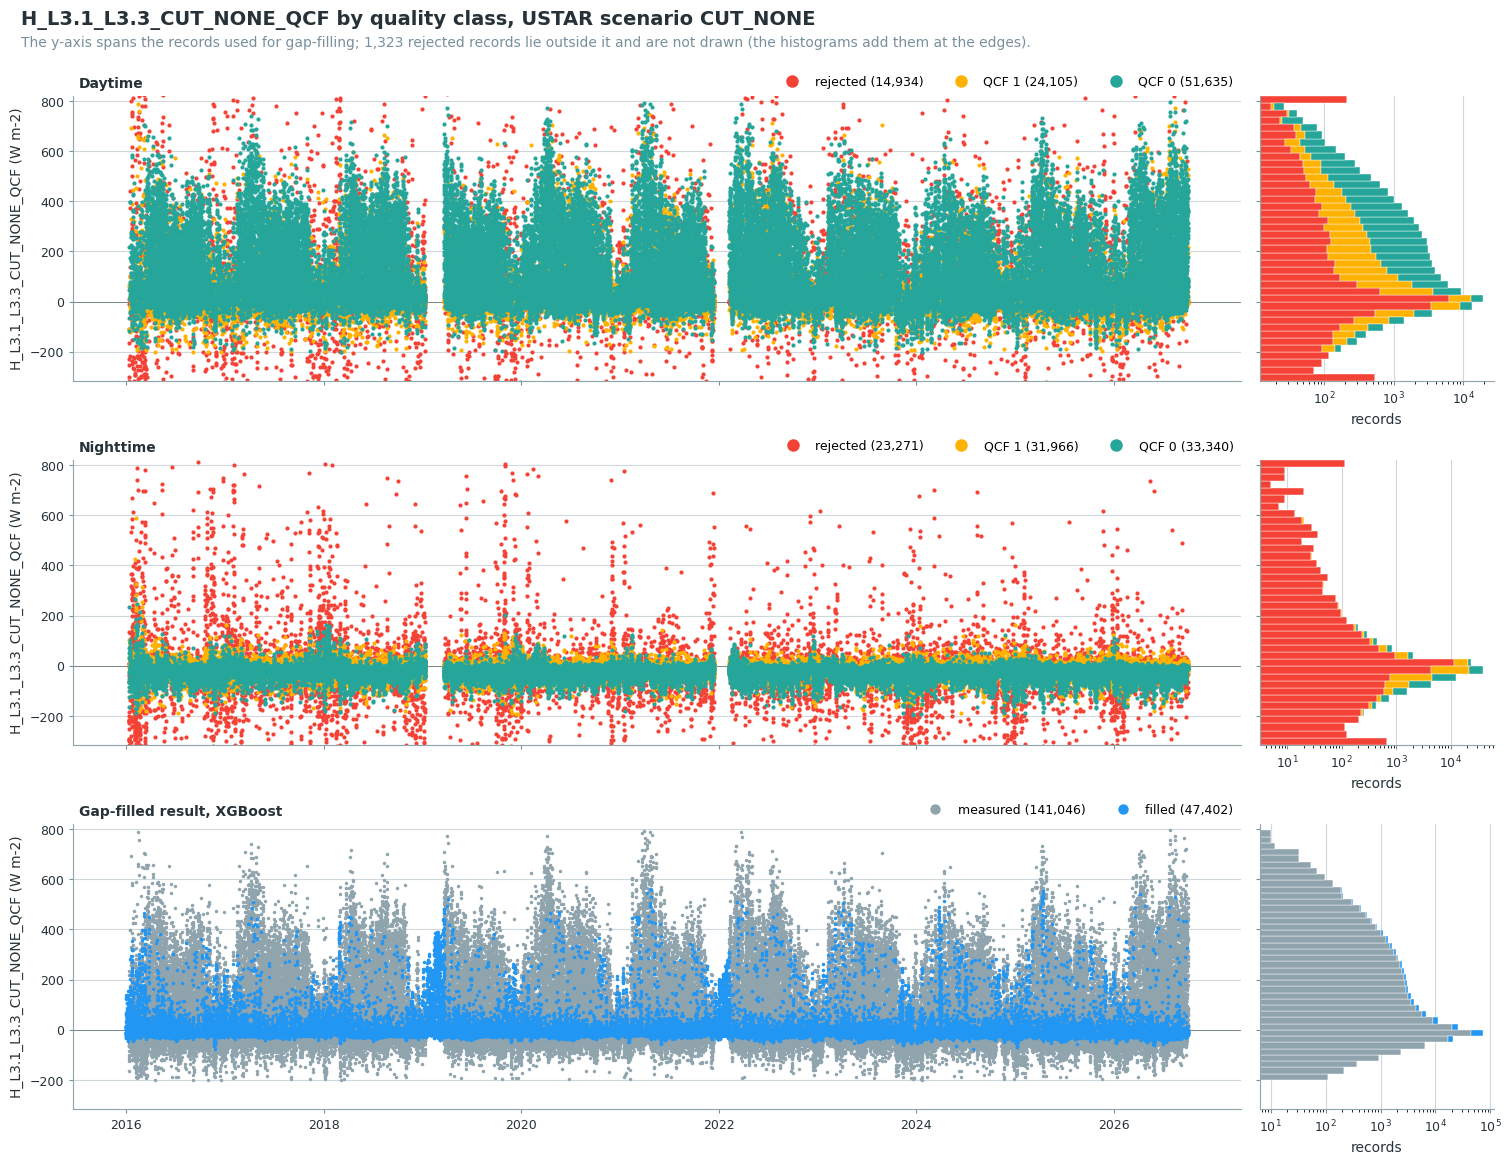

In [43]:
plot_quality_timeseries(data, ustar_scenario=SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux

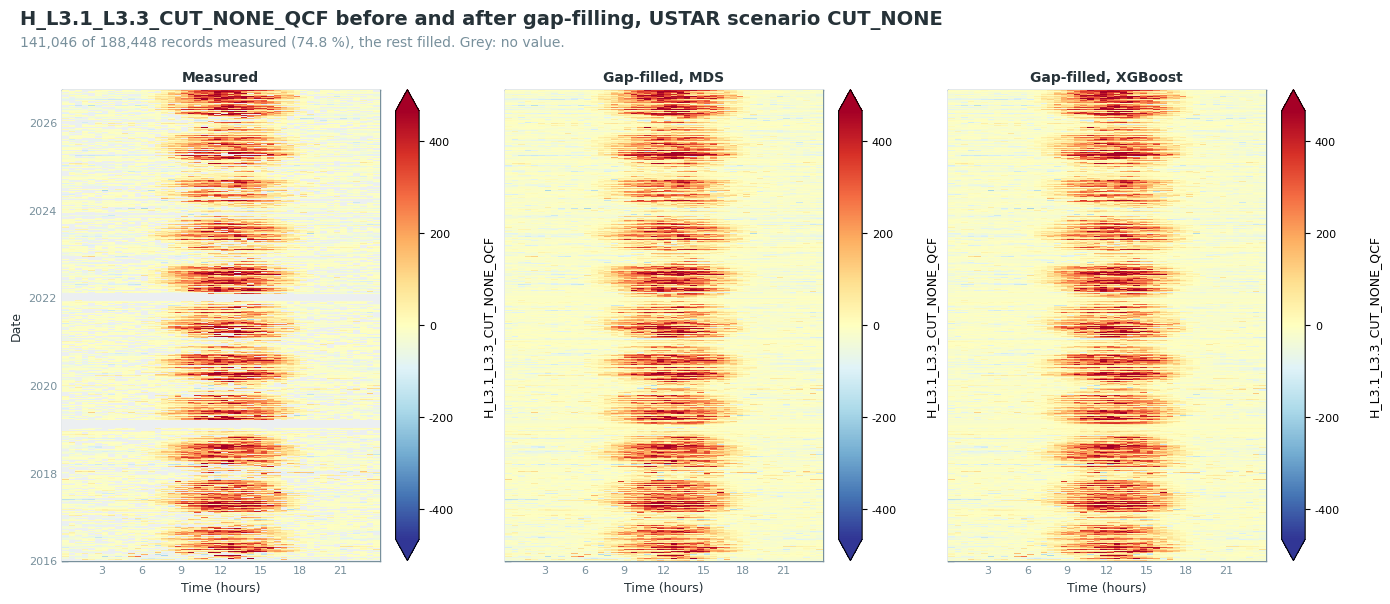

In [44]:
data.plot_gapfilled_heatmaps(ustar_scenario=SCENARIO)

### 📊 Plot: cumulative flux

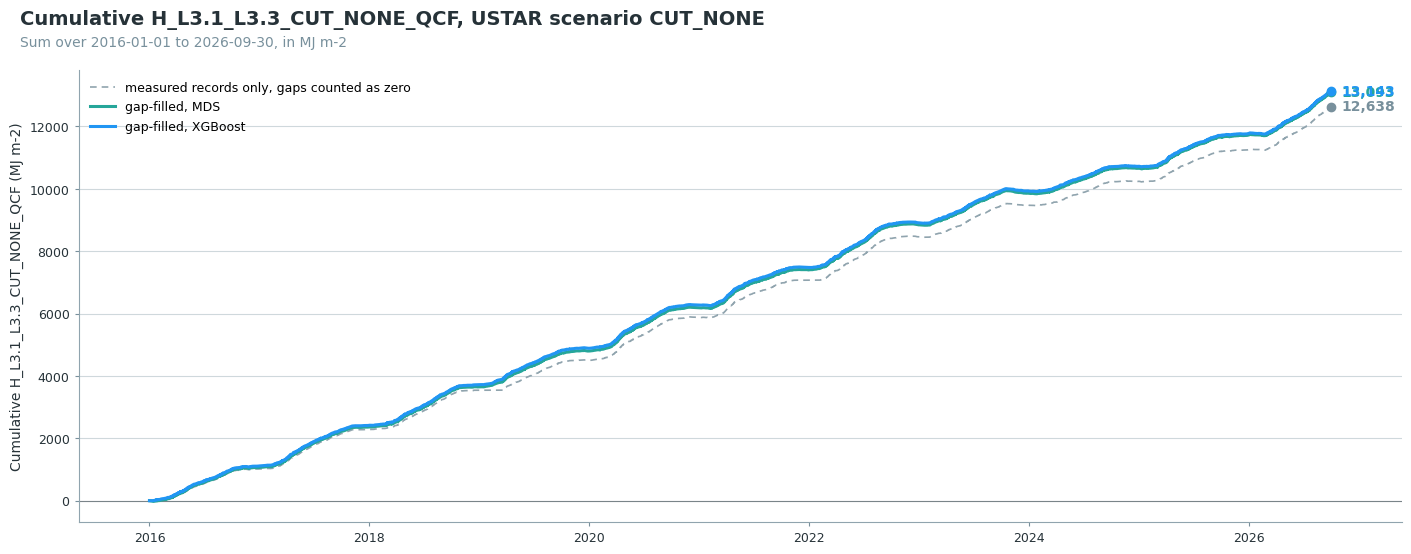

In [45]:
data.plot_cumulative_comparison(
    ustar_scenario=SCENARIO,
    conv_factor=WM2_TO_MJ,
    units='MJ m-2',
)

### 📊 Plot: cumulative flux of both gap-filling methods

One line per gap-filling method, each in its own colour, over the whole processed period.

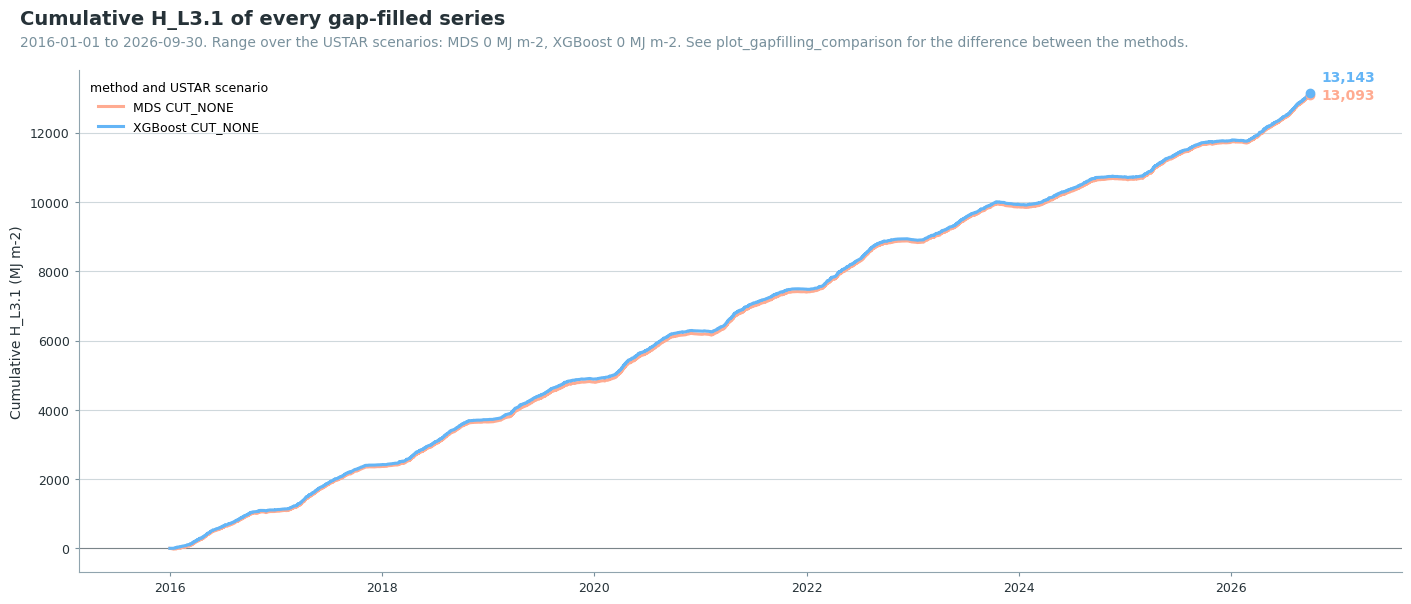

In [46]:
plot_gapfilled_cumulative(
    data,
    gain=WM2_TO_MJ,
    units='MJ m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year

One panel per gap-filling method, on the same y-axis. One line per year; the band is the mean ± 1 SD
of the full years. An incomplete last year is left out of the band.

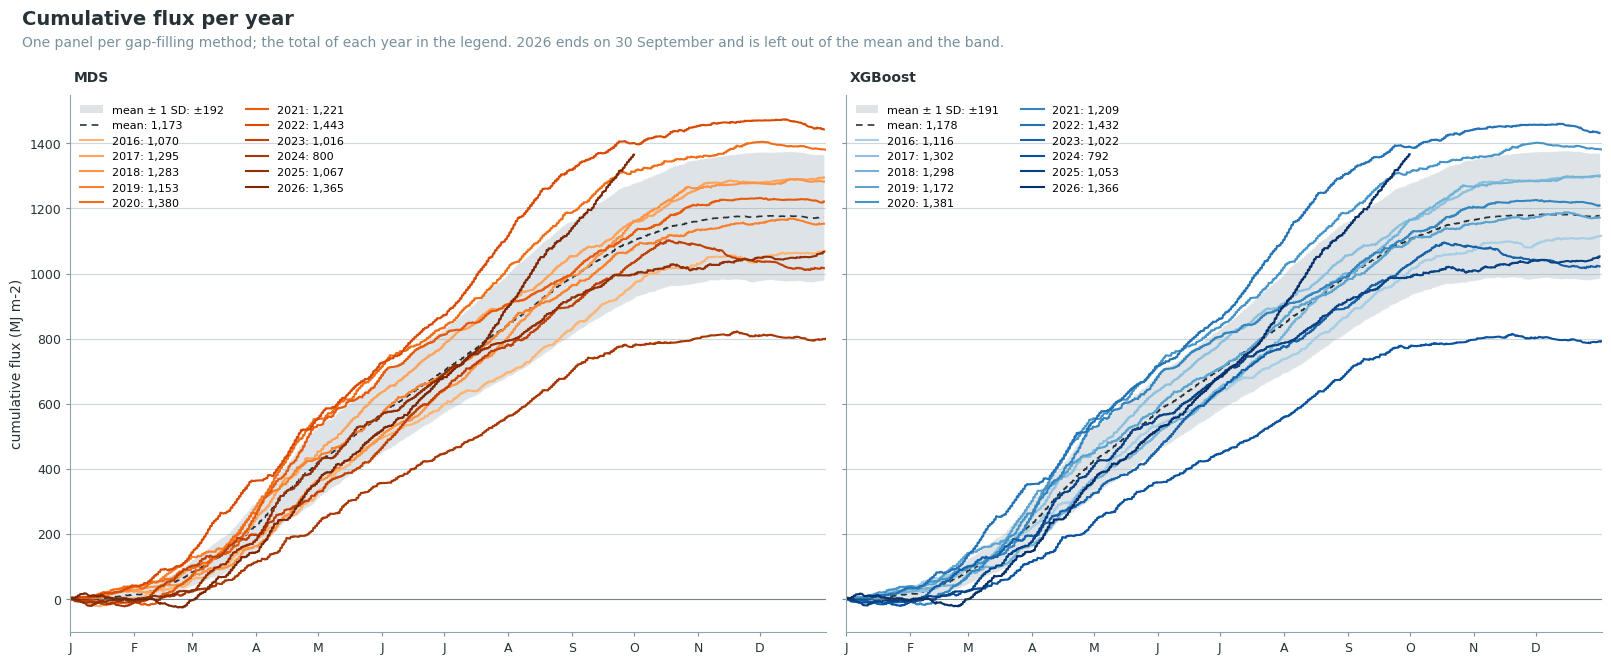

In [47]:
# One panel per gap-filling method, on a shared y-axis. Years run from light to dark, so the most
# recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(1, len(_gf), figsize=(8 * len(_gf), 6.6), sharex=True, sharey=True,
                         layout='constrained', squeeze=False)
for _ax, (_method, _cols) in zip(axes[0], _gf.items()):
    _cum = doy_cumulatives_per_year(data.fpc_df[_cols[SCENARIO]] * WM2_TO_MJ)
    _cum = _cum.loc[:, _cum.notna().any()]
    _years = list(_cum.columns)
    _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
        np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
    if len(_years) > 1:
        _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                   excl_years_from_reference=_partial)
        # Day 366 exists only in leap years, so the band stops before it.
        _ref = _ref.loc[_ref.index < 366]
        # The legend gives the mean and SD of the annual totals of the full years.
        _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
        _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
        _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                         alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
        _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                 linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
    for _shade, _year in zip(_shades, _years):
        _valid = _cum[_year].dropna()
        _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                 label=f"{_year}: {_valid.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _names.get(_method, _method))
    _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
    _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
axes[0][0].set_ylabel('cumulative flux (MJ m-2)')
_subtitle = "One panel per gap-filling method; the total of each year in the legend."
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative flux per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [48]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=WM2_TO_MJ, units='MJ m-2');

Gap-filling methods compared: MDS and XGBoost
              sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR         MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   13,093    13,143           50         72          -22    -11     -2      17     46
Sums (MJ m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_NONE, same 35,260 held-out records: MDS R² 0.84 RMSE 49.86, XGBoost R² 0.86 RMSE 46.09
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference.

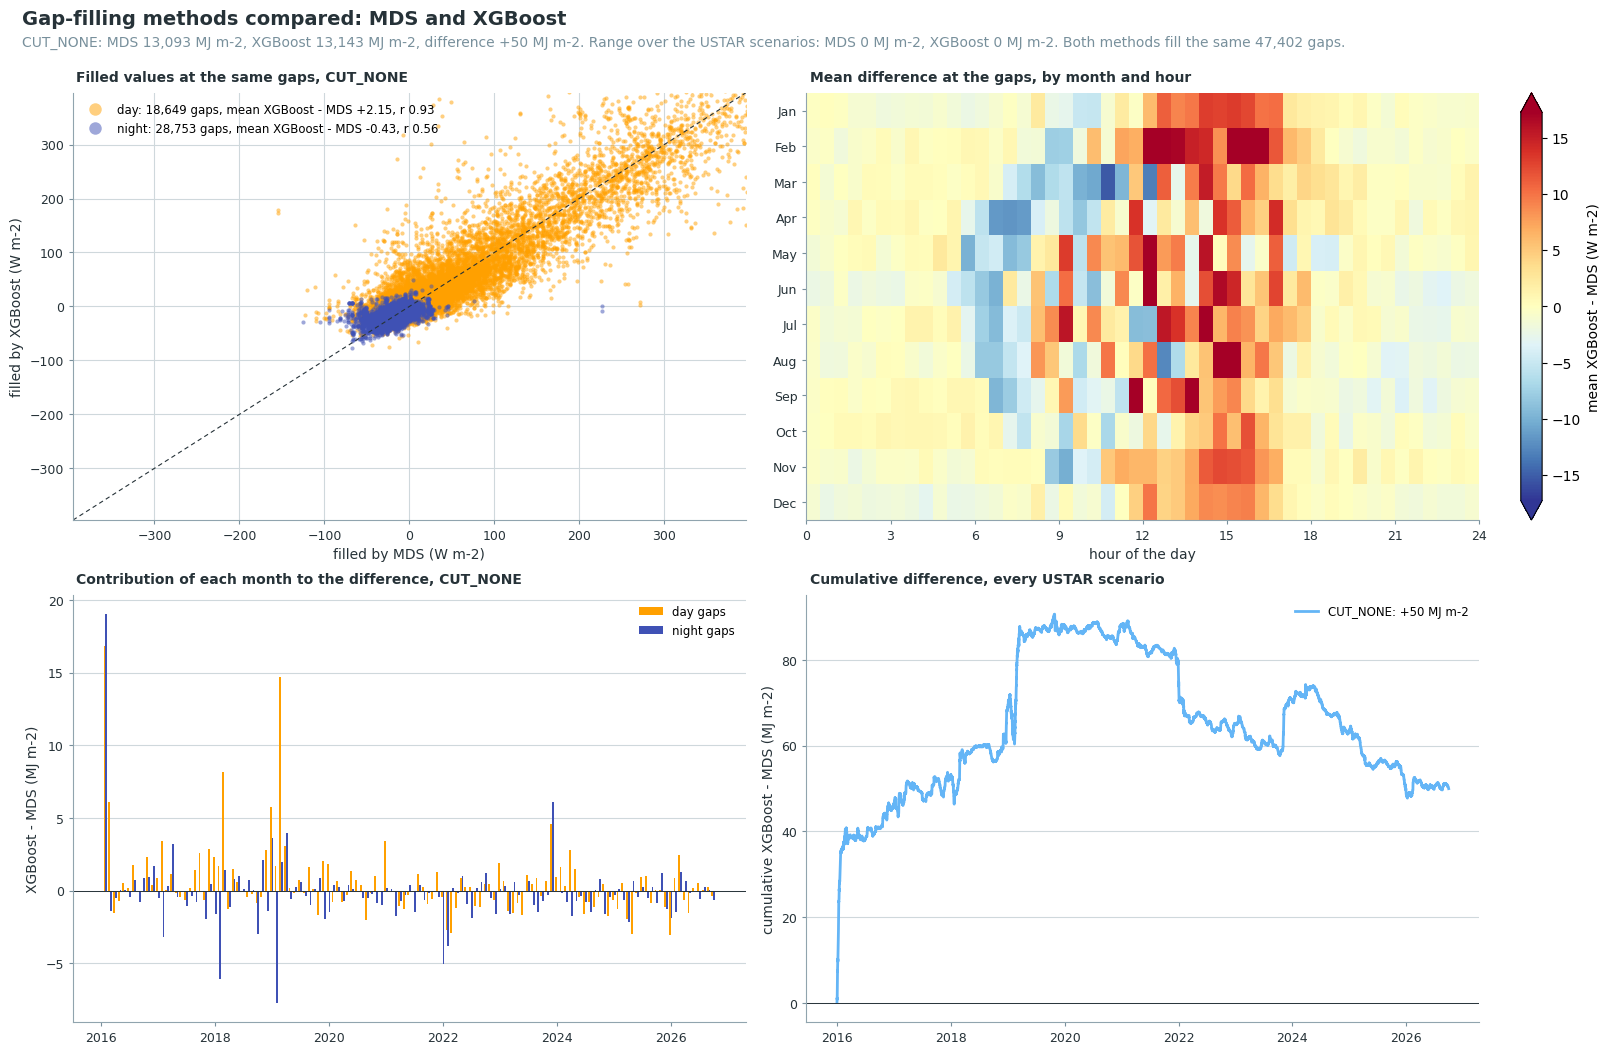

In [49]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario=SCENARIO, methods=('mds', 'xgb'),
                               gain=WM2_TO_MJ, units='MJ m-2', flux_units=FLUX_UNITS);

## 💾 Step 11: export

The output file holds only the columns this notebook adds: the flags and series of every level and
the gap-filled flux. The input columns stay in the input file; the merge into the fullset joins the
flux outputs with it on the timestamp.

In [50]:
_all = data.merged_df()
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns "
      f"(input columns left out: {_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 40 (L2: 12, L3.1: 7, L3.2: 10, L3.3: 7, L4.1:
4)

> No variables in the input data were overwritten, only new variables added.

188,448 records x 43 columns (input columns left out: 347)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\35_FPPC_IRGA72_H_2016-2026.09.parquet (0.468 seconds).

***

# End of notebook.

In [51]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-29 11:00:42
Finished: 2026-10-29 11:24:00
Runtime:  00:23:18 (hh:mm:ss)
